# CTGAN for Tabular Data Generation
Using SDV library as production baseline — conditional tabular GAN

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import SingleTableMetadata

df = pd.read_csv('../data/adult_clean.csv')
print('Shape:', df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [2]:
# Define metadata — tells CTGAN which columns are categorical vs numerical
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(df)
print('Detected metadata:')
print(metadata.to_dict())

Detected metadata:
{'METADATA_SPEC_VERSION': 'SINGLE_TABLE_V1', 'columns': {'age': {'sdtype': 'numerical'}, 'workclass': {'sdtype': 'categorical'}, 'fnlwgt': {'sdtype': 'numerical'}, 'education': {'sdtype': 'categorical'}, 'education_num': {'sdtype': 'numerical'}, 'marital_status': {'sdtype': 'categorical'}, 'occupation': {'sdtype': 'categorical'}, 'relationship': {'sdtype': 'categorical'}, 'race': {'sdtype': 'categorical'}, 'sex': {'sdtype': 'categorical'}, 'capital_gain': {'sdtype': 'numerical'}, 'capital_loss': {'sdtype': 'numerical'}, 'hours_per_week': {'sdtype': 'numerical'}, 'native_country': {'sdtype': 'categorical'}, 'income': {'sdtype': 'categorical'}}}


In [3]:
# Train CTGAN
synthesizer = CTGANSynthesizer(
    metadata,
    epochs=300,
    batch_size=500,
    verbose=True
)
synthesizer.fit(df)
print('CTGAN training complete!')

  0%|                                                  | 0/300 [00:00<?, ?it/s]

Gen. (+00.00) | Discrim. (+00.00):   0%|               | 0/300 [00:00<?, ?it/s]

Gen. (+02.17) | Discrim. (-00.39):   0%|               | 0/300 [00:05<?, ?it/s]

Gen. (+02.17) | Discrim. (-00.39):   0%|       | 1/300 [00:05<28:05,  5.64s/it]

Gen. (+01.57) | Discrim. (+00.04):   0%|       | 1/300 [00:07<28:05,  5.64s/it]

Gen. (+01.57) | Discrim. (+00.04):   1%|       | 2/300 [00:07<16:37,  3.35s/it]

... (594 outputs left out)

Gen. (-00.55) | Discrim. (-00.10): 100%|████▉| 299/300 [09:02<00:01,  1.75s/it]

Gen. (-00.55) | Discrim. (-00.10): 100%|█████| 300/300 [09:02<00:00,  1.75s/it]

Gen. (-00.55) | Discrim. (-00.10): 100%|█████| 300/300 [09:02<00:00,  1.81s/it]

CTGAN training complete!


In [4]:
# Generate synthetic data
synthetic_df = synthesizer.sample(num_rows=len(df))
synthetic_df.to_csv('../data/synthetic_ctgan.csv', index=False)
synthesizer.save('../models/ctgan_synthesizer.pkl')
print('CTGAN synthetic data saved:', synthetic_df.shape)
synthetic_df.head()

CTGAN synthetic data saved: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,52,Private,247574,Some-college,10,Married-civ-spouse,Adm-clerical,Husband,White,Male,7661,0,40,United-States,1
1,30,Local-gov,243354,Assoc-acdm,13,Never-married,Sales,Own-child,White,Male,0,0,58,United-States,0
2,22,?,141132,11th,7,Never-married,?,Own-child,Black,Male,10,0,22,United-States,0
3,24,Federal-gov,166317,Some-college,10,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,40,Vietnam,1
4,22,Private,169531,HS-grad,9,Never-married,Sales,Unmarried,Asian-Pac-Islander,Female,0,1794,30,United-States,0


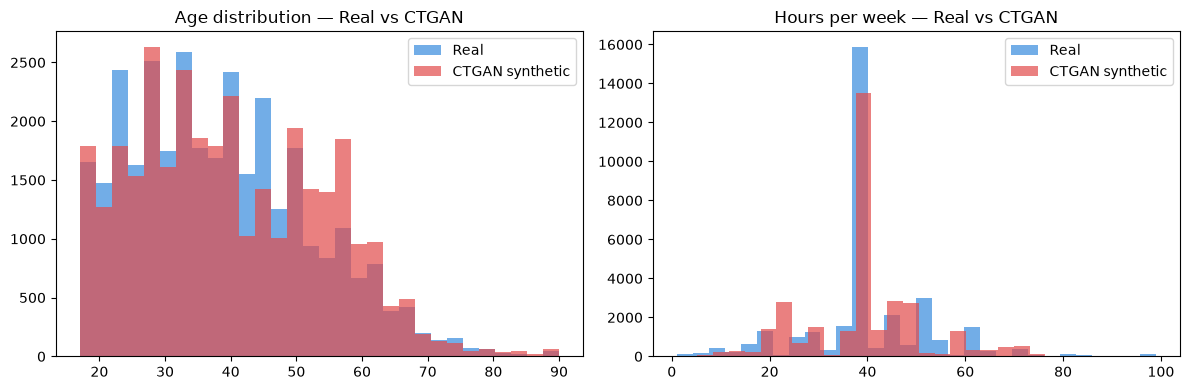

In [5]:
# Quick visual check — compare age distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['age'], bins=30, alpha=0.7, color='#378ADD', label='Real')
axes[0].hist(synthetic_df['age'], bins=30, alpha=0.7, color='#E24B4A', label='CTGAN synthetic')
axes[0].set_title('Age distribution — Real vs CTGAN')
axes[0].legend()

axes[1].hist(df['hours_per_week'], bins=30, alpha=0.7, color='#378ADD', label='Real')
axes[1].hist(synthetic_df['hours_per_week'], bins=30, alpha=0.7, color='#E24B4A', label='CTGAN synthetic')
axes[1].set_title('Hours per week — Real vs CTGAN')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/ctgan_preview.png', dpi=150, bbox_inches='tight')
plt.show()